# Oligodendroglioma example

Here we run infercnvpy on the example dataset of R inferCNV, a small dataset of malignant and non-malignant
cells from oligodendroglioma by {cite:t}`Tirosh2016`.
The [inferCNV wiki](https://github.com/broadinstitute/inferCNV/wiki#demo-example-figure) shows the heatmap that R
inferCNV draws for the same data, for comparison. For the full workflow, with clustering, CNV scores and tumor calls,
see the lung cancer tutorial ({doc}`tutorial_3k`).

In [1]:
import scanpy as sc

import infercnvpy as cnv

sc.set_figure_params(figsize=(5, 5), dpi=100, ipython_format="png")

## Prepare and inspect dataset

The example dataset is available in the `datasets` module. It is already normalized, but not log-transformed.

In [2]:
adata = cnv.datasets.oligodendroglioma()
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 184 × 9450
    obs: 'cell_type'
    var: 'chromosome', 'start', 'end', 'n_counts', 'n_cells'
    uns: 'cell_type_colors', 'log1p'
    layers: None (.X)

The genomic positions of the genes are already annotated in `adata.var`:

In [3]:
adata.var.head()

,chromosome,start,end,n_counts,n_cells
gene_symbol,,,,,
WASH7P,chr1,14363,29806,534.271301,116
LINC00115,chr1,761586,762902,203.649094,18
NOC2L,chr1,879584,894689,880.449707,63
SDF4,chr1,1152288,1167411,1013.251404,70
UBE2J2,chr1,1189289,1209265,411.488953,33


It contains malignant cells from four tumors and two types of non-malignant cells. The groups malignant_93 and
malignant_97 are the tumors MGH93 and MGH97, named as in the R example. For a quick overview, we draw a UMAP of the
gene expression.

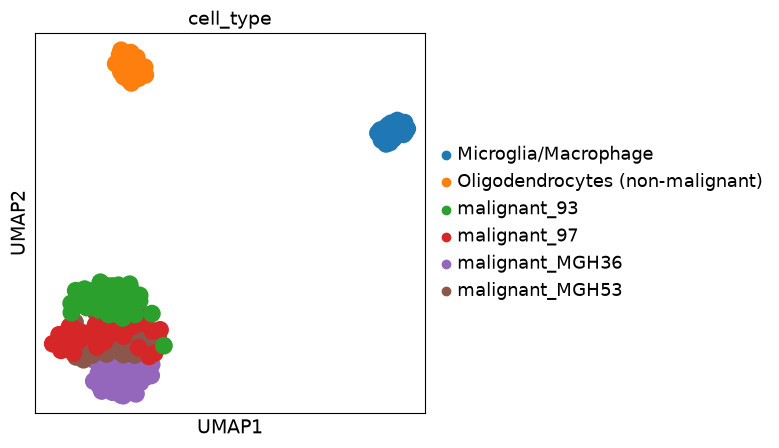

In [4]:
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.pl.umap(adata, color="cell_type")

## Run infercnvpy

We know which cells are non-malignant, and we use them as the reference with `reference_key` and `reference_cat`. The
non-malignant oligodendrocytes share the lineage of the tumor cells, so expression specific to the lineage cancels
out, and the microglia add a second, unrelated cell type. To stay close to the R example, we compute every window
(`step=1`) of 100 genes (R: 101). R's example also drops genes with a mean count below 1 (`cutoff=1`), and we keep all
genes here. `min_mean=1` applies a similar cutoff.

In [5]:
cnv.tl.infercnv(
    adata,
    reference_key="cell_type",
    reference_cat=["Oligodendrocytes (non-malignant)", "Microglia/Macrophage"],
    window_size=100,
    step=1,
)

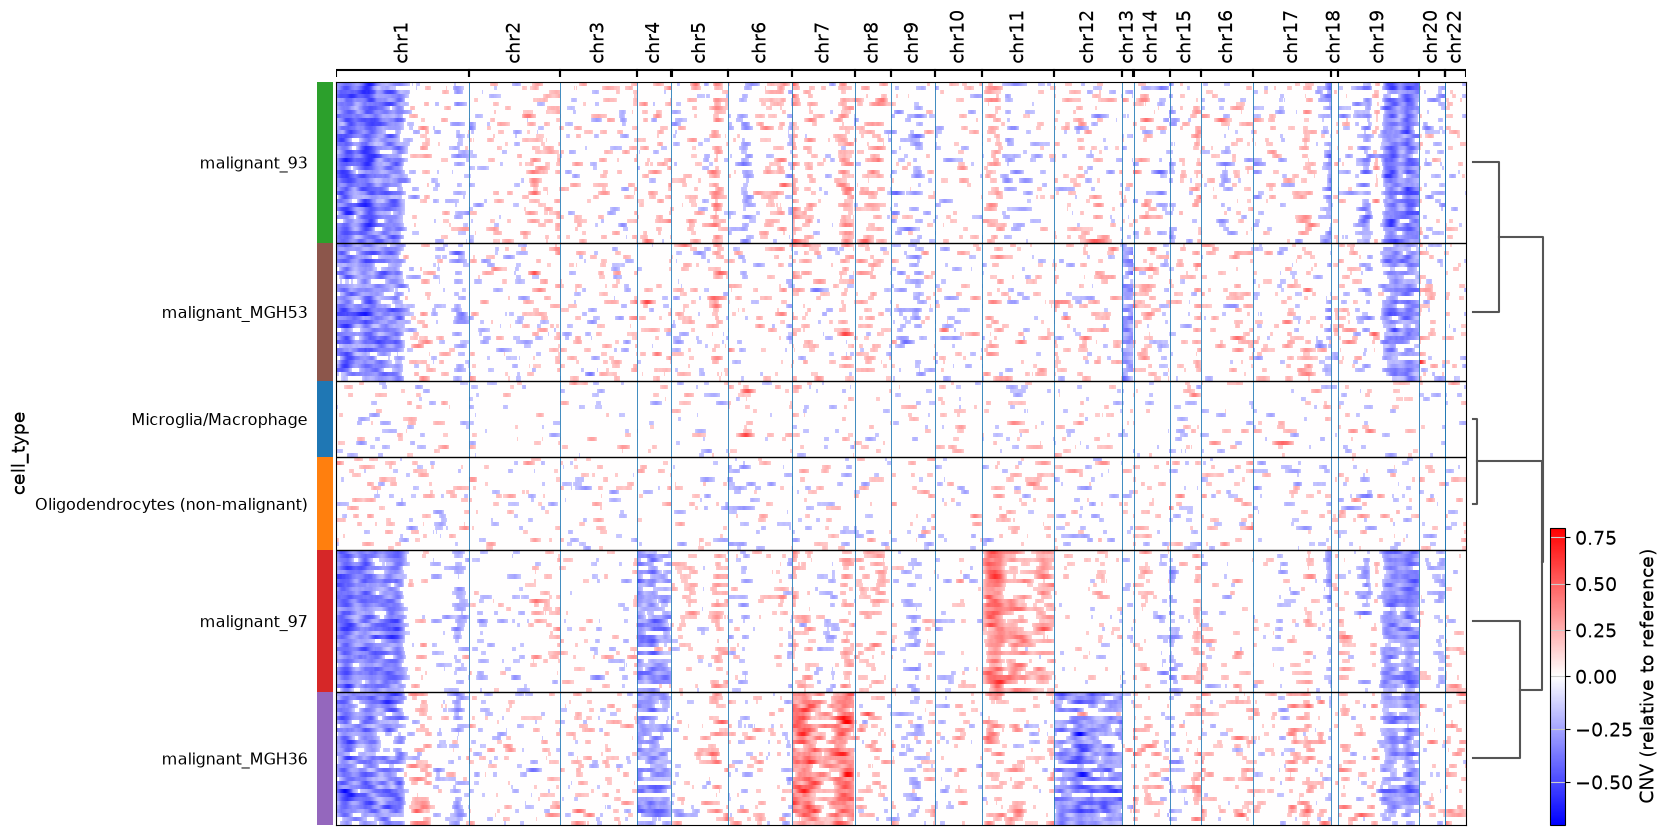

In [6]:
cnv.pl.chromosome_heatmap(adata, groupby="cell_type", dendrogram=True)

The heatmap shows the CNV signal, i.e. expression relative to the reference cells, not measured copy number. As in the
heatmap of R inferCNV, all four malignant groups show the loss of 1p and 19q, a codeletion that, together with an IDH
mutation, defines oligodendroglioma. Some groups have further changes, e.g. the gains of chromosome 7 in MGH36 and of
chromosome 11 in malignant_97. Chromosome 4 is lost in MGH36 and malignant_97, chromosome 12 in MGH36 and chromosome
13 in MGH53.